# Titanic Dataset Exploratory Data Analysis (EDA)
**Objective:** Clean, explore, and visualize the Titanic passenger dataset using Python (`Pandas` & `Matplotlib`) to identify key factors influencing survival rates.

In [1]:
import pandas as pd

df = pd.read_csv('titanic.csv')
print(df.head())

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN        S  


## 1. Data Loading & Initial Inspection

In [2]:
print(df.shape)

print(df.columns)

print(df.dtypes)

print(df.tail())

df.info()

(891, 12)
Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='str')
PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object
     PassengerId  Survived  Pclass                                      Name  \
886          887         0       2                     Montvila, Rev. Juozas   
887          888         1       1              Graham, Miss. Margaret Edith   
888          889         0       3  Johnston, Miss. Catherine Helen "Carrie"   
889          890         1       1                     Behr, Mr. Karl Howell   
890          891         0       3                       Dooley, Mr. Patrick   

        Sex   Age  SibSp  Parch      Ticket   Fare Cabin Embarked  
8

In [3]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


## 2. Data Cleaning & Missing Values Handling

In [4]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Missing Values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Duplicate Rows:
0


In [5]:
df_clean = df.copy()
df_clean["Age"] = df_clean["Age"].fillna(df_clean["Age"].median())
df_clean["Cabin"] = df_clean["Cabin"].fillna("Unknown")
df_clean["Embarked"] = df_clean["Embarked"].fillna(df_clean["Embarked"].mode()[0])


In [6]:
print("Missing Values After Cleaning:")
print(df_clean.isnull().sum())

print("\nDataset Shape:")
print(df_clean.shape)

print("\nDuplicate Rows:")
print(df_clean.duplicated().sum())

Missing Values After Cleaning:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin          0
Embarked       0
dtype: int64

Dataset Shape:
(891, 12)

Duplicate Rows:
0


## 3. Exploratory Data Analysis (EDA)

In [7]:
survival_by_sex = df_clean.groupby("Sex")["Survived"].agg(
    ["count", "sum", "mean"]
)

survival_by_sex["mean"] = survival_by_sex["mean"] * 100

print(survival_by_sex.round(2))


        count  sum   mean
Sex                      
female    314  233  74.20
male      577  109  18.89


###**Analysis:** Survival Rate by Gender

Results:
- Female: 74.20% (233 out of 314)
- Male: 18.89% (109 out of 577)

Insight: Female passengers had a significantly higher survival rate than male passengers.


In [8]:
survival_by_class = df_clean.groupby("Pclass")["Survived"].agg(
    ["count", "sum", "mean"]
)

survival_by_class["mean"] = survival_by_class["mean"] * 100

print(survival_by_class.round(2))

        count  sum   mean
Pclass                   
1         216  136  62.96
2         184   87  47.28
3         491  119  24.24


###**Analysis**: Survival Rate by Passenger Class

**Results:**
- First Class: 62.96%
- Second Class: 47.28%
- Third Class: 24.24%

**Insight:** First-class passengers had the highest survival rate, while third-class passengers had the lowest.

In [9]:
survival_by_port = df_clean.groupby("Embarked")["Survived"].agg(
    ["count", "sum", "mean"]
)

survival_by_port["mean"] = survival_by_port["mean"] * 100

print(survival_by_port.round(2))

          count  sum   mean
Embarked                   
C           168   93  55.36
Q            77   30  38.96
S           646  219  33.90


###**Analysis**: Survival Rate by Embarked

**Results:**
- Cherbourg (C): 55.36%
- Queenstown (Q): 38.96%
- Southampton (S): 33.90%

**Insight:** Passengers who embarked at Cherbourg had the highest survival rate, while Southampton had the lowest.

In [10]:
age_by_survival = df_clean.groupby("Survived")["Age"].agg(
    ["count", "mean", "median"]
)

print(age_by_survival.round(2))

          count   mean  median
Survived                      
0           549  30.03    28.0
1           342  28.29    28.0


###**Analysis: Survival by Age**

**Results:**
- Did not survive: Average age 30.63 years (424 passengers).
- Survived: Average age 28.34 years (290 passengers).
- Median age: 28 years for both groups.

**Insight:** Survivors were slightly younger on average, but the median age was the same in both groups.

In [11]:
df_clean["FamilySize"] = df_clean["SibSp"] + df_clean["Parch"] + 1

survival_by_family = df_clean.groupby("FamilySize")["Survived"].agg(
    ["count", "sum", "mean"]
)

survival_by_family["mean"] = survival_by_family["mean"] * 100

print(survival_by_family.round(2))

            count  sum   mean
FamilySize                   
1             537  163  30.35
2             161   89  55.28
3             102   59  57.84
4              29   21  72.41
5              15    3  20.00
6              22    3  13.64
7              12    4  33.33
8               6    0   0.00
11              7    0   0.00


###**Analysis: Survival by Family Size**

**Results:**
- Solo passengers: 30.35% survival rate.
- Family size 2–4: Higher survival rates (55.28%–72.41%).
- Family size 5 or more: Generally lower survival rates.

**Insight:** Passengers traveling in small families had higher observed survival rates than solo passengers and larger family groups.

In [12]:
fare_by_survival = df_clean.groupby("Survived")["Fare"].agg(
    ["count", "mean", "median"]
)

print(fare_by_survival.round(2))

          count   mean  median
Survived                      
0           549  22.12    10.5
1           342  48.40    26.0


###**Analysis: Survival by Fare**

**Results:**
- Survived: Average fare 48.40, median 26.00.
- Did not survive: Average fare 22.12, median 10.50.

**Insight:** Passengers who survived generally paid higher ticket fares than those who did not survive.

## 4. Correlation Analysis & Visualizations

In [13]:
correlation = df_clean[
    ["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare", "FamilySize"]
].corr()

print(correlation.round(2))

            Survived  Pclass   Age  SibSp  Parch  Fare  FamilySize
Survived        1.00   -0.34 -0.06  -0.04   0.08  0.26        0.02
Pclass         -0.34    1.00 -0.34   0.08   0.02 -0.55        0.07
Age            -0.06   -0.34  1.00  -0.23  -0.17  0.10       -0.25
SibSp          -0.04    0.08 -0.23   1.00   0.41  0.16        0.89
Parch           0.08    0.02 -0.17   0.41   1.00  0.22        0.78
Fare            0.26   -0.55  0.10   0.16   0.22  1.00        0.22
FamilySize      0.02    0.07 -0.25   0.89   0.78  0.22        1.00


In [16]:
import matplotlib.pyplot as plt

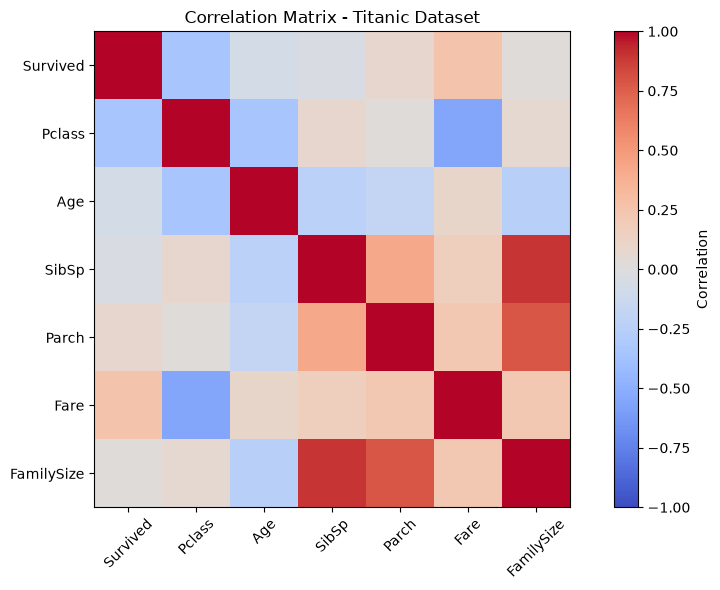

In [17]:
plt.figure(figsize=(9, 6))

plt.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)

plt.colorbar(label="Correlation")

plt.xticks(range(len(correlation.columns)), correlation.columns, rotation=45)
plt.yticks(range(len(correlation.index)), correlation.index)

plt.title("Correlation Matrix - Titanic Dataset")

plt.tight_layout()
plt.show()

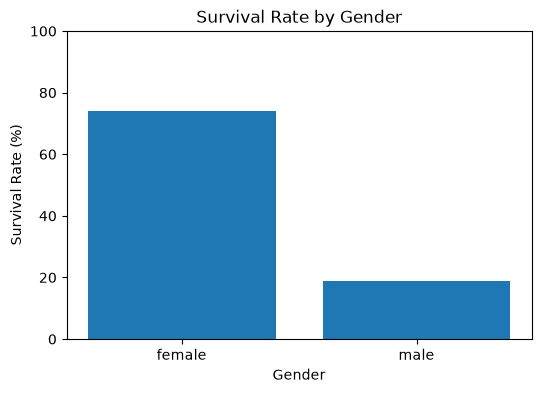

In [ ]:
plt.figure(figsize=(6, 4))

plt.bar(survival_by_sex.index, survival_by_sex["mean"])

plt.title("Survival Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Survival Rate (%)")
plt.ylim(0, 100)

plt.show()

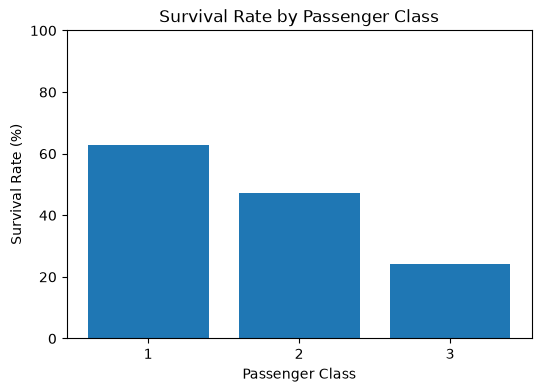

In [ ]:
plt.figure(figsize=(6, 4))

plt.bar(survival_by_class.index, survival_by_class["mean"])

plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate (%)")
plt.xticks([1, 2, 3])
plt.ylim(0, 100)

plt.show()

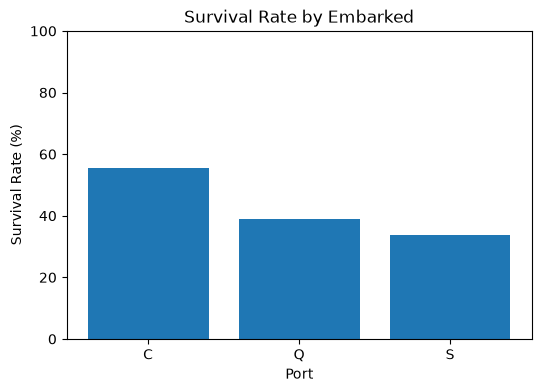

In [ ]:
plt.figure(figsize=(6, 4))

plt.bar(survival_by_port.index, survival_by_port["mean"])

plt.title("Survival Rate by Embarked")
plt.xlabel("Port")
plt.ylabel("Survival Rate (%)")
plt.ylim(0, 100)

plt.show()

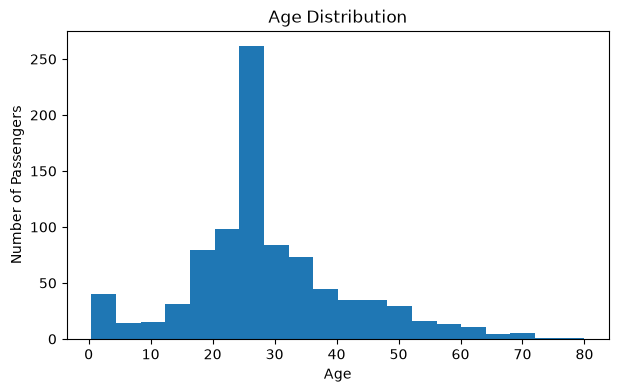

In [18]:
plt.figure(figsize=(7, 4))

plt.hist(df_clean["Age"].dropna(), bins=20)

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.show()

## 5. Summary of Key Findings & Recommendations

## Titanic Dataset Analysis

### 1. Project Overview
The goal of this project is to analyze the Titanic dataset using Python, Pandas, and Matplotlib to understand passenger data and identify factors associated with survival.

### 2. Key Findings
- The overall survival rate was approximately 38.38%.
- Female passengers had a higher survival rate (74.20%) than male passengers (18.89%).
- First-class passengers had a higher survival rate (62.96%) than third-class passengers (24.24%).
- Passengers who survived had a higher average ticket fare (48.40) than those who did not survive (22.12).
- Passengers traveling in small families generally had higher survival rates than solo passengers and larger families.

### 3. Correlation Analysis
The correlation analysis showed a negative relationship between passenger class and survival (-0.34), and a positive relationship between fare and survival (0.26).

### 4. Recommendations
- Consider passenger gender and class when studying survival patterns.
- Investigate the relationship between ticket fare and passenger class.
- Pay attention to missing values before making conclusions.
- Use the analysis results to understand patterns, not to assume direct causes of survival.

### 5. Conclusion
The analysis showed that survival rates differed across passenger groups. Gender and passenger class had noticeable relationships with survival, while age showed a smaller difference between survivors and non-survivors.